In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


In [2]:
df = pd.read_csv("Iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,setosa
1,2,4.9,3.0,1.4,0.2,setosa
2,3,4.7,3.2,1.3,0.2,setosa
3,4,4.6,3.1,1.5,0.2,setosa
4,5,5.0,3.6,1.4,0.2,setosa


In [3]:
df.shape

(150, 6)

In [4]:
df.tail()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,146,6.7,3.0,5.2,2.3,virginica
146,147,6.3,2.5,5.0,1.9,virginica
147,148,6.5,3.0,5.2,2.0,virginica
148,149,6.2,3.4,5.4,2.3,virginica
149,150,5.9,3.0,5.1,1.8,virginica


In [5]:
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')

In [6]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [8]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.057333,3.758000,1.199333
std,43.445368,0.828066,0.435866,1.765298,0.762238
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['Species'].unique()

<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

In [11]:
df['Species'].value_counts()

Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [12]:
df.dtypes

Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

In [13]:
df = df.drop("Id", axis = 1)
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [14]:
df.shape

(150, 5)

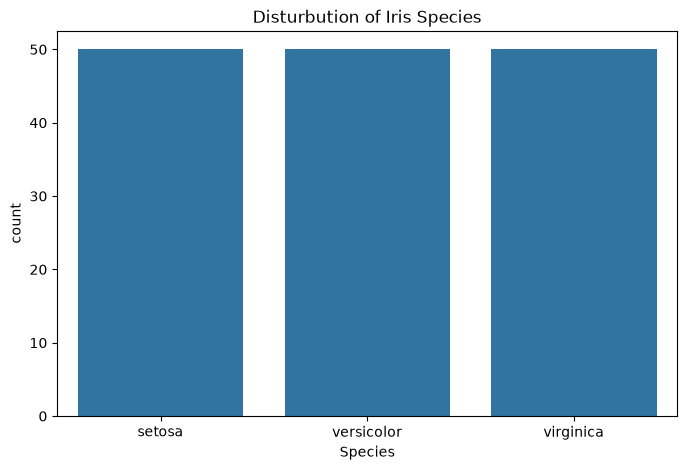

In [15]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Species")
plt.title("Disturbution of Iris Species")
plt.xlabel
plt.ylabel
plt.show()

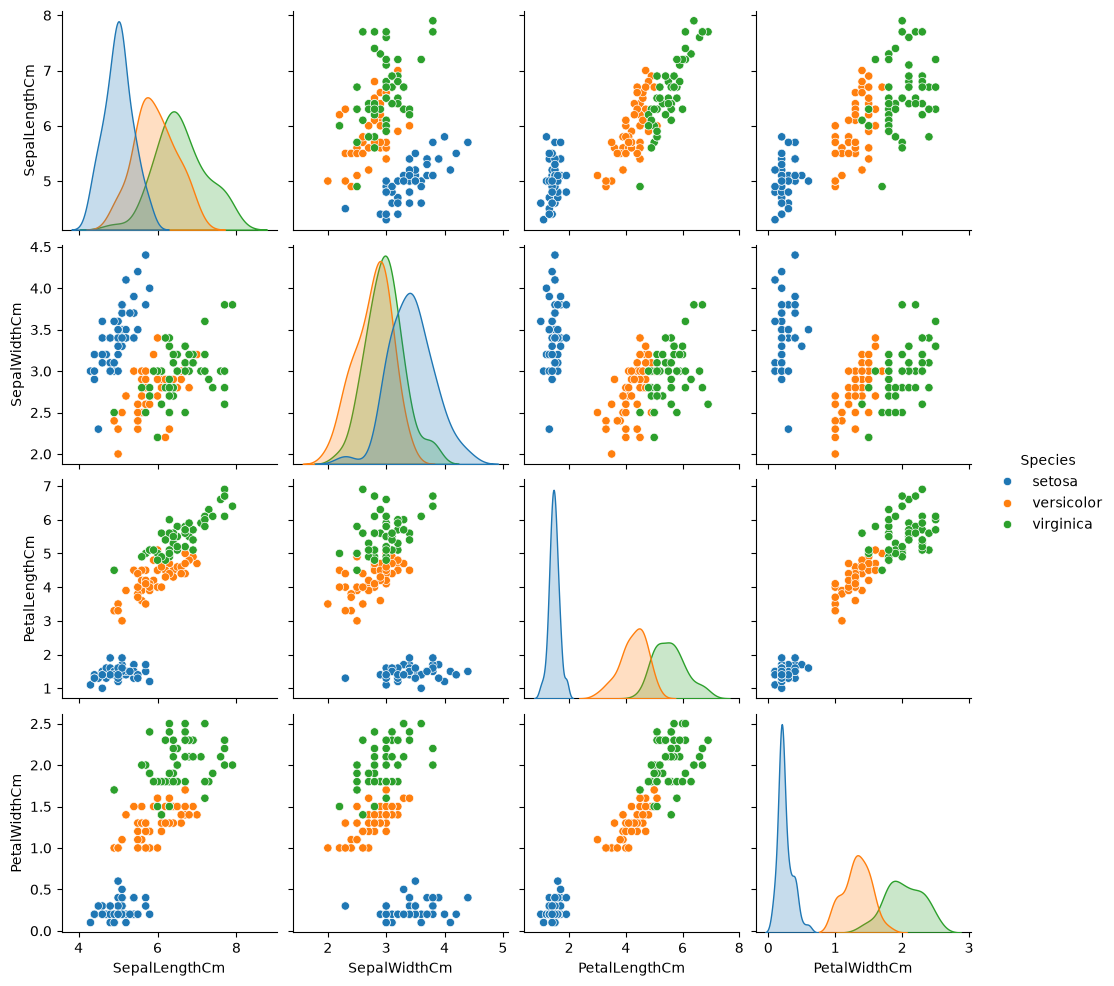

In [17]:
sns.pairplot(df, hue = "Species")
plt.show()

In [ ]:
plt.figure(df)

In [18]:
X = df.drop("Species", axis = 1)
y = df["Species"]

print("feature shape:", X.shape)
print("Target shape:", y.shape)


feature shape: (150, 4)
Target shape: (150,)


In [19]:
X.columns

Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'], dtype='str')

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2, random_state=42,stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train :", y_train.shape)
print("y_test shape:", y_test.shape)



X_train shape: (120, 4)
X_test: (30, 4)
y_train : (120,)
y_test shape: (30,)


In [ ]:
Scaler = StandardScaler()


In [31]:
X_train_scaled = Scaler.fit_transform(X_train)
X_test_scaled = Scaler.transform(X_test)

In [33]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [35]:
print("Original training shape :",X_train.shape)
print("PCA training shape:",X_train_pca.shape)
print("Original training shape :",X_test.shape)
print("PCA training shape :",X_test_pca.shape)

Original training shape : (120, 4)
PCA training shape: (120, 2)
Original training shape : (30, 4)
PCA training shape : (30, 2)


In [36]:
X_train_pca[:5]

array([[-2.35430673, -1.03369922],
       [ 0.32811646, -1.48461375],
       [ 1.2290844 , -0.08852476],
       [-2.19452009, -0.41449679],
       [ 0.24248823, -1.27773347]])

In [40]:
explained_variance = pca.explained_variance_ratio_

print("PC1 :", explained_variance[0])
print("PC2 :", explained_variance[1])


PC1 : 0.7267723404902057
PC2 : 0.2306666701643306


In [ ]:
#accuracy_score or baaki sab khud se